# Probability for Machine Learning

Machine-learning models make predictions under uncertainty. Probability gives us the language for
that uncertainty: distributions describe data, likelihood describes model fit, and Bayes' theorem
updates beliefs when evidence arrives.

## Learning objectives

By the end of this notebook you can:

- describe discrete and continuous random variables with distributions;
- compute expectation, variance, covariance, and correlation;
- use conditional probability, independence, and Bayes' theorem correctly;
- estimate parameters with maximum likelihood;
- explain how likelihood connects to log loss and model training.

## 1. Random variables and distributions

A random variable maps outcomes to numbers. A **discrete** variable has a probability mass function
(PMF); a **continuous** variable has a probability density function (PDF). Probabilities are always
between 0 and 1, and total probability is 1.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

### Bernoulli and binomial

A Bernoulli trial has two outcomes, usually 1 (success) with probability $p$ and 0 with probability
$1-p$. The binomial distribution counts successes in $n$ independent Bernoulli trials.

In [2]:
p = 0.3
n_trials = 10

bernoulli = stats.bernoulli(p)
binomial = stats.binom(n_trials, p)

print("P(Bernoulli = 1):", bernoulli.pmf(1))
print("E[Bernoulli]:", bernoulli.mean())
print("Var[Bernoulli]:", bernoulli.var())
print("P(Binomial = 4):", binomial.pmf(4))
print("E[Binomial]:", binomial.mean())
print("Var[Binomial]:", binomial.var())

P(Bernoulli = 1): 0.3
E[Bernoulli]: 0.3
Var[Bernoulli]: 0.21
P(Binomial = 4): 0.2001209489999999
E[Binomial]: 3.0
Var[Binomial]: 2.0999999999999996


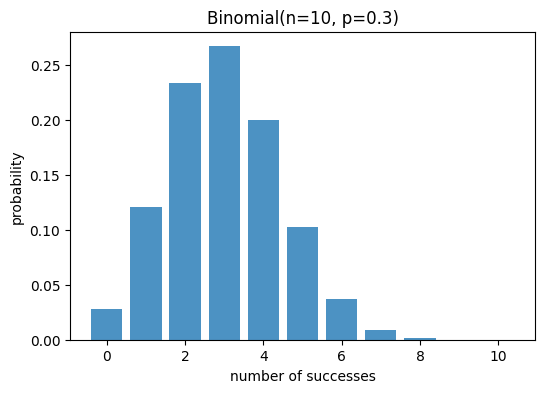

In [3]:
ks = np.arange(0, 11)
plt.figure(figsize=(6, 4))
plt.bar(ks, binomial.pmf(ks), alpha=0.8)
plt.xlabel("number of successes")
plt.ylabel("probability")
plt.title(f"Binomial(n={n_trials}, p={p})")
plt.show()

### Poisson

The Poisson distribution models the number of events in a fixed interval when events occur
independently at a constant average rate $\lambda$. It is common for counts such as arrivals,
failures, or clicks.

E[Poisson]: 3.0
Var[Poisson]: 3.0
P(Poisson = 3): 0.22404180765538775


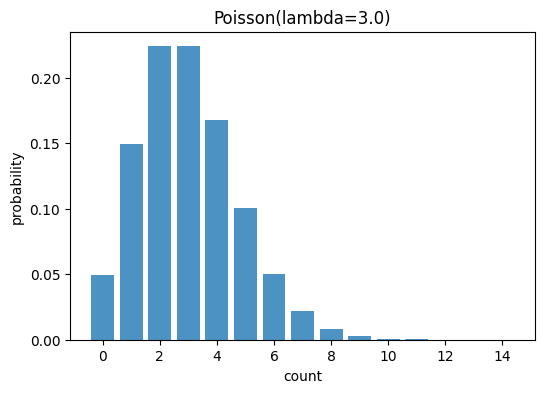

In [4]:
lam = 3.0
poisson = stats.poisson(lam)
ks = np.arange(0, 15)

print("E[Poisson]:", poisson.mean())
print("Var[Poisson]:", poisson.var())
print("P(Poisson = 3):", poisson.pmf(3))

plt.figure(figsize=(6, 4))
plt.bar(ks, poisson.pmf(ks), alpha=0.8)
plt.xlabel("count")
plt.ylabel("probability")
plt.title(f"Poisson(lambda={lam})")
plt.show()

### Uniform and normal

The uniform distribution gives equal density over an interval. The normal distribution is the
bell-shaped distribution at the center of statistics and the central limit theorem.

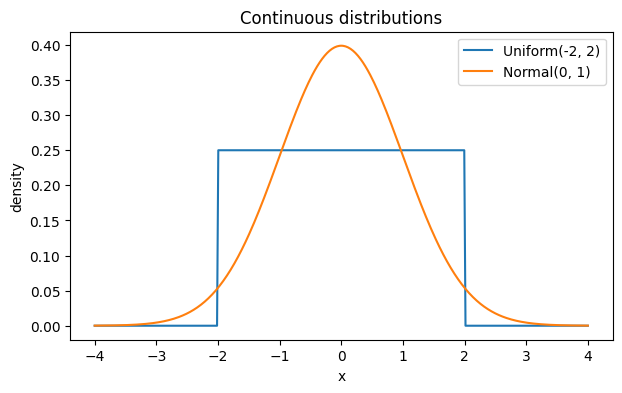

Normal 95% interval: (-1.959963984540054, 1.959963984540054)
P(-1 < Z < 1): 0.6826894921370859


In [5]:
xs = np.linspace(-4, 4, 400)
uniform = stats.uniform(loc=-2, scale=4)
normal = stats.norm(loc=0, scale=1)

plt.figure(figsize=(7, 4))
plt.plot(xs, uniform.pdf(xs), label="Uniform(-2, 2)")
plt.plot(xs, normal.pdf(xs), label="Normal(0, 1)")
plt.xlabel("x")
plt.ylabel("density")
plt.legend()
plt.title("Continuous distributions")
plt.show()

print("Normal 95% interval:", normal.interval(0.95))
print("P(-1 < Z < 1):", normal.cdf(1) - normal.cdf(-1))

## 2. Expectation, variance, and covariance

For a discrete variable $X$:

$$ E[X] = \sum_x x P(X=x), \qquad \mathrm{Var}(X) = E[(X-E[X])^2] $$

Variance measures spread. Covariance measures how two variables move together, and correlation
scales covariance to $[-1, 1]$ so it is easier to compare.

In [6]:
x = rng.normal(10, 2, 10_000)
y = 0.8 * x + rng.normal(0, 1, 10_000)

print("sample mean of x:", x.mean())
print("sample variance of x:", x.var(ddof=1))
print("sample covariance:", np.cov(x, y, ddof=1)[0, 1])
print("sample correlation:", np.corrcoef(x, y)[0, 1])
print("theoretical correlation is close to:",
      0.8 / np.sqrt(0.8**2 + 1.0**2))

sample mean of x: 9.979500249171977
sample variance of x: 4.0508492767684094
sample covariance: 3.215493056168778
sample correlation: 0.8469611986825436
theoretical correlation is close to: 0.6246950475544243


Correlation measures **linear** association only. A correlation near zero does not imply independence:
a strong non-linear relationship can have zero correlation.

In [7]:
z = rng.uniform(-1, 1, 5000)
w = z ** 2
print("correlation(z, z^2):", np.corrcoef(z, w)[0, 1])

correlation(z, z^2): -0.01625920552394166


## 3. Conditional probability and independence

The conditional probability of $A$ given $B$ is

$$ P(A \mid B) = \frac{P(A \cap B)}{P(B)} $$

Events are independent when $P(A \cap B) = P(A)P(B)$, equivalently $P(A \mid B) = P(A)$.
Independence is a strong assumption; dependent observations require different models and validation
schemes.

In [8]:
total = 1000
has_disease = 10
test_positive_given_disease = 0.99
test_positive_given_healthy = 0.05

tp = has_disease * test_positive_given_disease
fp = (total - has_disease) * test_positive_given_healthy
positive = tp + fp

print("true positives:", tp)
print("false positives:", fp)
print("total positives:", positive)
print("P(disease | positive):", tp / positive)

true positives: 9.9
false positives: 49.5
total positives: 59.4
P(disease | positive): 0.16666666666666669


This is the **base-rate fallacy**. Even with a 99% sensitive test, a positive result can imply a low
probability of disease when the disease is rare. Always combine the test likelihood with the prior
prevalence.

## 4. Bayes' theorem

$$ P(H \mid E) = \frac{P(E \mid H) P(H)}{P(E)} $$

- $P(H)$ is the **prior**;
- $P(E \mid H)$ is the **likelihood**;
- $P(H \mid E)$ is the **posterior**;
- $P(E)$ is the **evidence**, which normalizes the posterior.

Bayes' theorem is the foundation of Naive Bayes, Bayesian updating, and many probabilistic models.

In [9]:
priors = np.array([0.01, 0.99])
likelihoods = np.array([0.99, 0.05])
evidence = np.sum(priors * likelihoods)
posteriors = priors * likelihoods / evidence
print("posterior probability of disease:", posteriors[0])

# Sequential updating: a second independent positive test
posterior_after_first = posteriors[0]
prior_second = np.array([posterior_after_first, 1 - posterior_after_first])
evidence_second = np.sum(prior_second * likelihoods)
posterior_second = prior_second[0] * likelihoods[0] / evidence_second
print("posterior after a second positive test:", posterior_second)

posterior probability of disease: 0.16666666666666669
posterior after a second positive test: 0.7983870967741936


### Bayes with a spam filter

A simple spam filter uses word likelihoods. The posterior odds form is often more convenient:

$$ \frac{P(\text{spam} \mid w)}{P(\text{ham} \mid w)} =
\frac{P(w \mid \text{spam})}{P(w \mid \text{ham})}
\frac{P(\text{spam})}{P(\text{ham})} $$

This is exactly the logic behind multinomial Naive Bayes in `m10.ipynb`.

In [10]:
prior_spam = 0.4
p_word_spam = 0.20
p_word_ham = 0.02

posterior_spam = (p_word_spam * prior_spam) / (
    p_word_spam * prior_spam + p_word_ham * (1 - prior_spam)
)
print("P(spam | word):", posterior_spam)
print("posterior odds:", posterior_spam / (1 - posterior_spam))
print("prior odds:", prior_spam / (1 - prior_spam))
print("likelihood ratio:", p_word_spam / p_word_ham)

P(spam | word): 0.8695652173913044
posterior odds: 6.666666666666671
prior odds: 0.6666666666666667
likelihood ratio: 10.0


## 5. Common distributions and when to use them

| Distribution | Support | Typical use |
| --- | --- | --- |
| Bernoulli | 0/1 | one binary outcome |
| Binomial | 0..n | number of successes in $n$ trials |
| Poisson | 0, 1, 2, ... | event counts in an interval |
| Uniform | interval | no prior preference over a range |
| Normal | real line | measurement noise, sums of many effects |
| Exponential | positive reals | waiting times between Poisson events |
| Beta | [0, 1] | uncertainty about a probability |

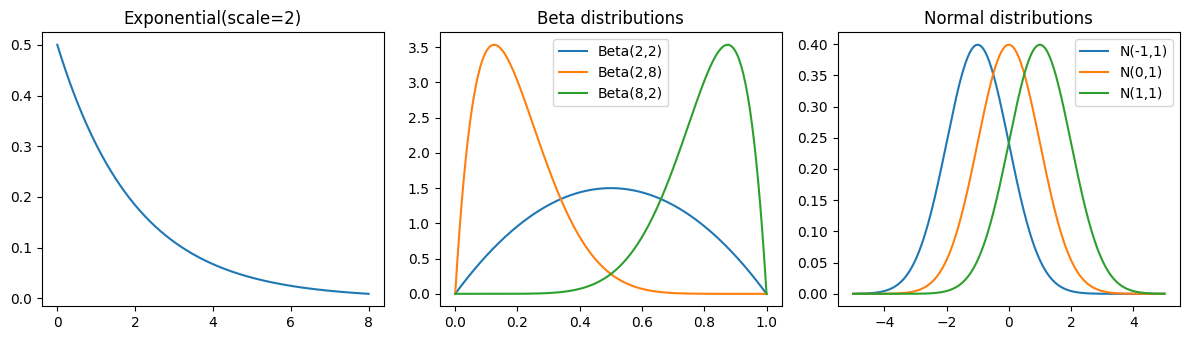

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

xs = np.linspace(0, 8, 300)
axes[0].plot(xs, stats.expon(scale=2).pdf(xs))
axes[0].set_title("Exponential(scale=2)")

ps = np.linspace(0, 1, 300)
for a, b in [(2, 2), (2, 8), (8, 2)]:
    axes[1].plot(ps, stats.beta(a, b).pdf(ps), label=f"Beta({a},{b})")
axes[1].set_title("Beta distributions")
axes[1].legend()

xs = np.linspace(-5, 5, 300)
for mu in [-1, 0, 1]:
    axes[2].plot(xs, stats.norm(mu, 1).pdf(xs), label=f"N({mu},1)")
axes[2].set_title("Normal distributions")
axes[2].legend()

plt.tight_layout()
plt.show()

## 6. Maximum likelihood estimation

Given independent observations, the likelihood is the product of the probability (or density) of each
observation. Maximizing the likelihood is equivalent to maximizing the log-likelihood, which is
numerically safer and turns products into sums.

For Bernoulli data, the MLE is the sample proportion. For normal data, the MLE of the mean is the
sample mean and the MLE of the variance uses division by $n$ rather than $n-1$.

Bernoulli MLE p_hat: 0.69
Normal MLE mu: 4.97854279610754
Normal MLE sigma: 2.0066832582165466
p that maximizes log-likelihood: 0.6895979899497487


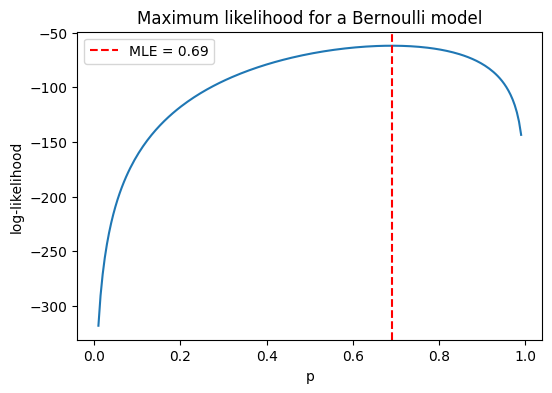

In [12]:
coin_flips = rng.binomial(1, 0.65, 100)
p_hat = coin_flips.mean()
print("Bernoulli MLE p_hat:", p_hat)

normal_data = rng.normal(5, 2, 500)
mu_hat = normal_data.mean()
sigma_hat = normal_data.std(ddof=0)
print("Normal MLE mu:", mu_hat)
print("Normal MLE sigma:", sigma_hat)

# log-likelihood as a function of p
ps = np.linspace(0.01, 0.99, 200)
log_likelihood = np.array([
    np.sum(coin_flips * np.log(p) + (1 - coin_flips) * np.log(1 - p))
    for p in ps
])
best_p = ps[np.argmax(log_likelihood)]
print("p that maximizes log-likelihood:", best_p)

plt.figure(figsize=(6, 4))
plt.plot(ps, log_likelihood)
plt.axvline(best_p, color="red", linestyle="--", label=f"MLE = {best_p:.2f}")
plt.xlabel("p")
plt.ylabel("log-likelihood")
plt.title("Maximum likelihood for a Bernoulli model")
plt.legend()
plt.show()

The MLE can overfit small samples and is sensitive to rare events. **Maximum a posteriori (MAP)**
estimation adds a prior, which is equivalent to regularization. For example, a Beta prior on a
Bernoulli parameter leads to smoothed probability estimates.

In [13]:
alpha_prior, beta_prior = 2, 2
smoothed = (coin_flips.sum() + alpha_prior - 1) / (
    len(coin_flips) + alpha_prior + beta_prior - 2
)
print("MLE:", coin_flips.mean())
print("MAP with Beta(2,2):", smoothed)

MLE: 0.69
MAP with Beta(2,2): 0.6862745098039216


## 7. Monte Carlo and the law of large numbers

Monte Carlo methods approximate expectations by simulation. As the sample size grows, the sample
average converges to the true expectation. This is why simulation is a practical tool for checking
probability calculations and for approximating intractable integrals.

       n  sample_mean
0     10      11.5767
1     50      10.2252
2    100       9.9975
3    500      10.0514
4   1000      10.1511
5   5000       9.9856
6  20000       9.9715


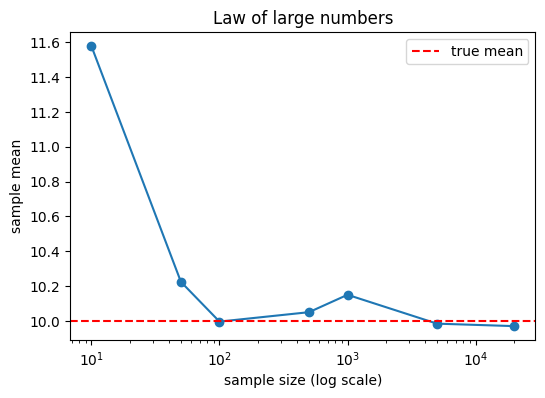

In [14]:
sample_sizes = [10, 50, 100, 500, 1000, 5000, 20000]
means = []
for n in sample_sizes:
    sample = rng.normal(10, 2, n)
    means.append(sample.mean())

print(pd.DataFrame({"n": sample_sizes, "sample_mean": np.round(means, 4)}))

plt.figure(figsize=(6, 4))
plt.plot(sample_sizes, means, marker="o")
plt.axhline(10, color="red", linestyle="--", label="true mean")
plt.xscale("log")
plt.xlabel("sample size (log scale)")
plt.ylabel("sample mean")
plt.title("Law of large numbers")
plt.legend()
plt.show()

In [15]:
# Monte Carlo estimate of a probability: P(Z > 1) for a standard normal
draws = rng.normal(0, 1, 200_000)
mc_estimate = np.mean(draws > 1)
exact = 1 - stats.norm.cdf(1)
print("Monte Carlo estimate:", mc_estimate)
print("exact value:", exact)
print("absolute error:", abs(mc_estimate - exact))

Monte Carlo estimate: 0.15792
exact value: 0.15865525393145707
absolute error: 0.0007352539314570694


## 8. Where probability appears in machine learning

- **Logistic regression** models $P(y=1 \mid x)$ with a sigmoid.
- **Log loss** is the negative log-likelihood of the observed labels.
- **Naive Bayes** applies Bayes' theorem with a conditional-independence assumption.
- **Calibration** checks whether predicted probabilities match observed frequencies.
- **Uncertainty quantification** uses distributions over parameters or predictions.

A model that outputs a probability is not automatically calibrated. The advanced calibration module
shows how to measure and improve probabilistic predictions.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from sklearn.metrics import log_loss

X, y = make_classification(
    n_samples=500, n_features=4, n_informative=3, n_redundant=0,
    random_state=42, class_sep=1.2
)
model = LogisticRegression().fit(X, y)
proba = model.predict_proba(X)[:, 1]
print("log loss:", log_loss(y, proba))
print("mean predicted probability:", proba.mean())
print("observed positive rate:", y.mean())

log loss: 0.23764207584974548
mean predicted probability: 0.5100143967531368
observed positive rate: 0.51


## 9. Summary

- Distributions describe uncertainty; choose one that matches the data-generating process.
- Expectation and variance summarize center and spread; covariance and correlation summarize
  association.
- Conditional probability and Bayes' theorem update priors with evidence.
- Maximum likelihood is the bridge from probability to model fitting.
- Monte Carlo turns probability calculations into simulations.
- Log loss, Naive Bayes, and calibration are direct applications in ML.

## Exercises

1. Simulate 10,000 draws from a Poisson distribution and compare the sample mean and variance with
   the theoretical values.
2. Compute the posterior probability of spam for two independent words using the odds form.
3. Derive the Bernoulli MLE by setting the derivative of the log-likelihood to zero.
4. Show that a Beta(1,1) prior gives the same MAP estimate as the MLE for a Bernoulli model.
5. Use Monte Carlo simulation to estimate $P(X > 2)$ for a Poisson(3) variable and compare with the
   exact value.